# FERPA Quantitative Study | RQ3 Statistical Tests

**Research question:** How do perceived FERPA compliance risk and comfort with
generative AI relate to educators' judgments across the nine scenarios?

**Study sample:** N = 100, matched to the original study roster by Prolific ID.

**Analyses:** Friedman tests, Kendall's W, selected Wilcoxon signed-rank tests,
Spearman correlations, selected Kruskal-Wallis tests, exploratory ordinal
Generalized Estimating Equations (GEE), and Holm multiple-test corrections.

This notebook uses only the structured responses. No written explanations,
codebook, or inter-rater analyses are included. Risk and comfort are perceptions,
not expert judgments about FERPA compliance. None of the tests proves causation.

## 1. Setup

Put the notebook, the two original input files, and no additional datasets in
the same working directory:

- `FERPA Survey July 24 2026 - N100 - Most Recent.xlsx`
- `FPEPG_October 26, 2026_06.13.csv`

Requires NumPy, SciPy, statsmodels, and Matplotlib. To install, use
`pip install numpy scipy statsmodels matplotlib` in the notebook's environment.
Standard-library tools handle XLSX/CSV reading. Source files are not changed.

In [1]:
from pathlib import Path
from zipfile import ZipFile
from xml.etree import ElementTree as ET
from collections import Counter
import csv
import re
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
from statsmodels.genmod.generalized_estimating_equations import OrdinalGEE
from statsmodels.genmod.cov_struct import Independence, Exchangeable

BASE = Path.cwd()
SAMPLE_FILE = BASE / "FERPA Survey July 24 2026 - N100 - Most Recent.xlsx"
QUALTRICS_FILE = BASE / "FPEPG_October 26, 2026_06.13.csv"
OUTPUT_DIR = BASE / "RQ3_outputs"
OUTPUT_DIR.mkdir(exist_ok=True)
N_EXPECTED = 100
SCENARIOS = [f"Scenario {i}" for i in range(1, 10)]
JUDGMENTS = ("Yes", "No", "Depends", "I do not know")
ALPHA = 0.05

for source in (SAMPLE_FILE, QUALTRICS_FILE):
    if not source.exists():
        raise FileNotFoundError(f"Missing {source.name}. Place both source files next to the notebook.")


def write_csv(filename, rows, columns):
    """Write aggregate results only. Participant IDs are never exported."""
    with (OUTPUT_DIR / filename).open("w", encoding="utf-8-sig", newline="") as handle:
        w = csv.DictWriter(handle, fieldnames=columns)
        w.writeheader()
        w.writerows([{c: row.get(c, "") for c in columns} for row in rows])


def pretty_p(p):
    return "< .001" if p < .001 else f"{p:.4f}"


def show_table(label, rows, cols):
    print("\n" + label)
    if not rows:
        print("No rows")
        return
    widths = {c: max(len(c), *(len(str(r.get(c, ""))) for r in rows)) for c in cols}
    print("  ".join(c.ljust(widths[c]) for c in cols))
    print("  ".join("-" * widths[c] for c in cols))
    for r in rows:
        print("  ".join(str(r.get(c, "")).ljust(widths[c]) for c in cols))


def holm_adjust(p_values):
    """Holm's step-down multiplicity adjustment, preserving the original order."""
    raw = np.asarray(p_values, dtype=float)
    if np.any(~np.isfinite(raw)) or np.any((raw < 0) | (raw > 1)):
        raise ValueError("Holm adjustment requires finite p-values between zero and one.")
    order = np.argsort(raw)
    adjusted = np.empty(len(raw), dtype=float)
    previous = 0.0
    for rank, idx in enumerate(order):
        previous = max(previous, min(1.0, (len(raw) - rank) * raw[idx]))
        adjusted[idx] = previous
    return adjusted

print("Output directory:", OUTPUT_DIR.resolve())

Output directory: /mnt/data/RQ3_outputs


## 2. Identify the established N = 100 sample and load the nine scenarios

The original workbook identifies the study's 100 participants. The Qualtrics
CSV provides the nine structured judgments and paired five-point risk and
comfort ratings. We match by Prolific ID; no additional participant is added.

**Important data-layout detail:** In the Qualtrics export, each `Scenario n`
heading is repeated for judgment and written explanation. Each `Scenario n_1`
heading is repeated for risk and comfort, in that order. The code checks the
question text and selects the correct columns by position, ignoring explanations.

In [2]:
_XML_NS = {"m": "http://schemas.openxmlformats.org/spreadsheetml/2006/main"}


def excel_col_index(ref):
    match = re.match(r"[A-Z]+", ref)
    if not match:
        raise ValueError(f"Invalid Excel reference {ref}")
    idx = 0
    for character in match.group():
        idx = idx * 26 + ord(character) - ord("A") + 1
    return idx - 1


def original_sample_ids(path):
    """Read the first worksheet via OOXML, without adding a spreadsheet dependency."""
    with ZipFile(path) as wb:
        shared = []
        if "xl/sharedStrings.xml" in wb.namelist():
            root = ET.fromstring(wb.read("xl/sharedStrings.xml"))
            for item in root.findall("m:si", _XML_NS):
                shared.append("".join((t.text or "") for t in item.findall(".//m:t", _XML_NS)))
        sheet = ET.fromstring(wb.read("xl/worksheets/sheet1.xml"))
        rows = []
        for xml_row in sheet.findall(".//m:sheetData/m:row", _XML_NS):
            cells = {}
            for cell in xml_row.findall("m:c", _XML_NS):
                index = excel_col_index(cell.attrib["r"])
                value_tag = cell.find("m:v", _XML_NS)
                cell_type = cell.attrib.get("t")
                if cell_type == "s" and value_tag is not None:
                    value = shared[int(value_tag.text)]
                elif cell_type == "inlineStr":
                    value = "".join((t.text or "") for t in cell.findall(".//m:t", _XML_NS))
                else:
                    value = value_tag.text if value_tag is not None else ""
                cells[index] = str(value or "").strip()
            rows.append(cells)
    if not rows:
        raise ValueError("The original study workbook is empty.")
    headers = {value: index for index, value in rows[0].items() if value}
    for label in ("Prolific ID", "Q1"):
        if label not in headers:
            raise ValueError(f"Missing original workbook column: {label}")
    pid_col, q1_col = headers["Prolific ID"], headers["Q1"]
    ids = {
        row.get(pid_col, "")
        for row in rows[1:]
        if row.get(pid_col, "") and row.get(q1_col, "") in {"True", "False", "Unsure"}
    }
    if len(ids) != N_EXPECTED:
        raise AssertionError(f"Expected the original sample N = 100; matched roster has {len(ids)} IDs")
    return ids


sample_ids = original_sample_ids(SAMPLE_FILE)
records = []
with QUALTRICS_FILE.open("r", encoding="utf-8-sig", newline="") as source:
    reader = csv.reader(source)
    header = next(reader)
    questions = next(reader)  # Full question wording
    next(reader)              # Qualtrics import metadata

    if "Prolific ID" not in header:
        raise ValueError("Updated Qualtrics export does not contain Prolific ID")
    pid_col = header.index("Prolific ID")
    field_indexes = {}
    for field in ("Q6_1", "Q15"):
        if field not in header:
            raise ValueError(f"Updated Qualtrics export missing {field}")
        field_indexes[field] = header.index(field)

    scenario_indexes = {}
    for i, name in enumerate(SCENARIOS, start=1):
        judgment_positions = [idx for idx, title in enumerate(header) if title == name]
        scale_positions = [idx for idx, title in enumerate(header) if title == f"{name}_1"]
        if len(judgment_positions) != 2 or len(scale_positions) != 2:
            raise ValueError(f"Unexpected column layout for {name}. Check original Qualtrics headers.")
        j_idx, risk_idx, comfort_idx = judgment_positions[0], scale_positions[0], scale_positions[1]
        if "risk" not in questions[risk_idx].lower() or "comfortable" not in questions[comfort_idx].lower():
            raise ValueError(f"Risk/comfort labels are not in expected positions for {name}")
        scenario_indexes[name] = (j_idx, risk_idx, comfort_idx)

    for raw in reader:
        pid = raw[pid_col].strip()
        if pid not in sample_ids:
            continue
        r = {"Prolific ID": pid, "Q6": raw[field_indexes["Q6_1"]].strip(),
             "Training": raw[field_indexes["Q15"]].strip()}
        for name, (j_idx, risk_idx, comfort_idx) in scenario_indexes.items():
            r[name] = {
                "Judgment": raw[j_idx].strip(),
                "Risk": raw[risk_idx].strip(),
                "Comfort": raw[comfort_idx].strip(),
            }
        records.append(r)

ids = [r["Prolific ID"] for r in records]
if len(records) != N_EXPECTED or len(set(ids)) != N_EXPECTED:
    raise AssertionError("The matched export must contain exactly 100 unique study participants.")

risk = np.empty((N_EXPECTED, len(SCENARIOS)), dtype=float)
comfort = np.empty_like(risk)
judgment = np.empty((N_EXPECTED, len(SCENARIOS)), dtype=object)
knowledge = np.empty(N_EXPECTED, dtype=float)
recent_training = np.empty(N_EXPECTED, dtype=int)
for row_idx, r in enumerate(records):
    knowledge[row_idx] = float(r["Q6"])
    if not 0 <= knowledge[row_idx] <= 10:
        raise ValueError("Unexpected Q6 self-assessed knowledge score")
    if r["Training"] not in ("Yes", "No"):
        raise ValueError("Unexpected FERPA training response")
    recent_training[row_idx] = int(r["Training"] == "Yes")
    for col_idx, name in enumerate(SCENARIOS):
        response = r[name]
        if response["Judgment"] not in JUDGMENTS:
            raise ValueError(f"Unexpected scenario judgment in {name}")
        judgment[row_idx, col_idx] = response["Judgment"]
        risk[row_idx, col_idx] = float(response["Risk"])
        comfort[row_idx, col_idx] = float(response["Comfort"])
        for val, variable in ((risk[row_idx, col_idx], "risk"),
                              (comfort[row_idx, col_idx], "comfort")):
            if not val.is_integer() or not 1 <= val <= 5:
                raise ValueError(f"Unexpected {variable} rating in {name}: {val}")

print("Validated study sample: N =", N_EXPECTED)
print("All nine scenarios have valid judgments, risk, and comfort ratings.")
print("Recent training: Yes =", int(recent_training.sum()),
      "No =", int((1 - recent_training).sum()))

Validated study sample: N = 100
All nine scenarios have valid judgments, risk, and comfort ratings.
Recent training: Yes = 52 No = 48


## 3. Descriptive results: risk, comfort, and judgment distributions

For each scenario, compute the average and median risk and comfort ratings,
and counts in the four judgment categories. Descriptive means are reported
for continuity with the existing study; the inferential tests below respect
the ordinal five-point scales.


Scenario-level risk / comfort descriptive statistics
Scenario    Mean risk  Median risk  Mean comfort  Median comfort
----------  ---------  -----------  ------------  --------------
Scenario 1  3.76       4.0          1.70          1.0           
Scenario 2  1.13       1.0          4.14          5.0           
Scenario 3  4.78       5.0          1.21          1.0           
Scenario 4  2.04       2.0          3.05          3.0           
Scenario 5  1.19       1.0          4.08          5.0           
Scenario 6  3.06       3.0          2.18          2.0           
Scenario 7  1.63       1.0          3.19          3.0           
Scenario 8  2.29       2.0          2.83          3.0           
Scenario 9  2.65       2.5          2.62          2.0           


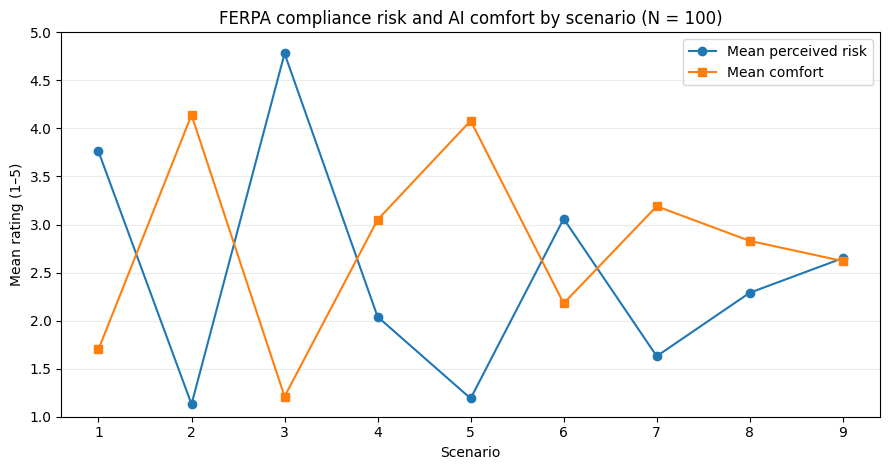

In [3]:
summary = []
for j, name in enumerate(SCENARIOS):
    counts = Counter(judgment[:, j].tolist())
    summary.append({
        "Scenario": name,
        "Mean risk": float(np.mean(risk[:, j])), "Median risk": float(np.median(risk[:, j])),
        "Mean comfort": float(np.mean(comfort[:, j])),
        "Median comfort": float(np.median(comfort[:, j])),
        **{f"Judgment {label}": int(counts[label]) for label in JUDGMENTS},
    })
summary_cols = ["Scenario", "Mean risk", "Median risk", "Mean comfort", "Median comfort"] + [
    f"Judgment {label}" for label in JUDGMENTS]
write_csv("RQ3_scenario_descriptive_summary.csv", summary, summary_cols)
show_table("Scenario-level risk / comfort descriptive statistics", [
    {**r, "Mean risk": f"{r['Mean risk']:.2f}", "Mean comfort": f"{r['Mean comfort']:.2f}"}
    for r in summary
], ["Scenario", "Mean risk", "Median risk", "Mean comfort", "Median comfort"])

fig, ax = plt.subplots(figsize=(9.0, 4.8))
x = np.arange(1, len(SCENARIOS)+1)
ax.plot(x, risk.mean(axis=0), marker="o", label="Mean perceived risk")
ax.plot(x, comfort.mean(axis=0), marker="s", label="Mean comfort")
ax.set(xlabel="Scenario", ylabel="Mean rating (1–5)", ylim=(1, 5),
       title="FERPA compliance risk and AI comfort by scenario (N = 100)")
ax.set_xticks(x)
ax.legend()
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "RQ3_risk_comfort_by_scenario.png", dpi=160)
plt.show()

## 4. Friedman tests and Kendall's W

Separate Friedman tests determine whether each educator's rankings of risk
and comfort differ across the nine *related* scenarios. Kendall's W reports
the effect size / ranking concordance. Friedman is an omnibus test; it does
not tell us which pairs differ. With N = 100 and nine scenarios, W is the
Friedman chi-square statistic divided by 100 × (9 − 1).

In [4]:
friedman_results = []
for label, matrix in (("Perceived risk", risk), ("Comfort with generative AI", comfort)):
    result = stats.friedmanchisquare(*[matrix[:, j] for j in range(matrix.shape[1])])
    w = float(result.statistic) / (matrix.shape[0] * (matrix.shape[1] - 1))
    friedman_results.append({
        "Outcome": label, "N educators": matrix.shape[0],
        "Number of scenarios": matrix.shape[1], "Friedman chi-square": float(result.statistic),
        "df": matrix.shape[1] - 1, "Unadjusted p": float(result.pvalue), "Kendall W": w,
    })
show_table("Friedman omnibus tests + Kendall's W", [{
    **r, "Friedman chi-square": f"{r['Friedman chi-square']:.3f}",
    "Unadjusted p": pretty_p(r["Unadjusted p"]), "Kendall W": f"{r['Kendall W']:.3f}",
} for r in friedman_results], ["Outcome", "Friedman chi-square", "df", "Unadjusted p", "Kendall W"])
write_csv("RQ3_friedman_kendall_w.csv", friedman_results,
          ["Outcome", "N educators", "Number of scenarios", "Friedman chi-square",
           "df", "Unadjusted p", "Kendall W"])


Friedman omnibus tests + Kendall's W
Outcome                     Friedman chi-square  df  Unadjusted p  Kendall W
--------------------------  -------------------  --  ------------  ---------
Perceived risk              524.964              8   < .001        0.656    
Comfort with generative AI  414.415              8   < .001        0.518    


## 5. Selected Wilcoxon signed-rank comparisons + Holm correction

These comparisons are **paired within educator**, not independent-group tests.
The preselected pairs are S7 versus S8 (related de-identification / vendor
handling situations) and S4 versus S6 (contextual identifiability situations).
We compare risk and comfort for both pairs, and apply one Holm adjustment
across the resulting four exploratory tests. We report direction with the
paired descriptive averages. The scenarios are not controlled experiments,
so observed differences cannot be attributed to a single scenario feature.

In [5]:
planned_pairs = [(7, 8), (4, 6)]
wilcoxon_results = []
for s1, s2 in planned_pairs:
    for label, matrix in (("Risk", risk), ("Comfort", comfort)):
        a, b = matrix[:, s1-1], matrix[:, s2-1]
        test = stats.wilcoxon(a, b, alternative="two-sided",
                              zero_method="wilcox", method="auto")
        wilcoxon_results.append({
            "Outcome": label, "Scenario A": s1, "Scenario B": s2,
            "Mean A": float(np.mean(a)), "Mean B": float(np.mean(b)),
            "Mean difference A minus B": float(np.mean(a-b)),
            "Wilcoxon W": float(test.statistic),
            "Unadjusted p": float(test.pvalue),
        })
for row, adj in zip(wilcoxon_results,
                    holm_adjust([r["Unadjusted p"] for r in wilcoxon_results])):
    row["Holm-adjusted p"] = float(adj)
    row["Significant after Holm"] = bool(adj < ALPHA)
show_table("Selected paired Wilcoxon comparisons", [{
    **r, "Mean A": f"{r['Mean A']:.2f}", "Mean B": f"{r['Mean B']:.2f}",
    "Unadjusted p": pretty_p(r["Unadjusted p"]),
    "Holm-adjusted p": pretty_p(r["Holm-adjusted p"]),
} for r in wilcoxon_results], ["Outcome", "Scenario A", "Scenario B", "Mean A", "Mean B",
                             "Unadjusted p", "Holm-adjusted p", "Significant after Holm"])
write_csv("RQ3_wilcoxon_selected_pairs_holm.csv", wilcoxon_results,
          ["Outcome", "Scenario A", "Scenario B", "Mean A", "Mean B",
           "Mean difference A minus B", "Wilcoxon W", "Unadjusted p",
           "Holm-adjusted p", "Significant after Holm"])


Selected paired Wilcoxon comparisons
Outcome  Scenario A  Scenario B  Mean A  Mean B  Unadjusted p  Holm-adjusted p  Significant after Holm
-------  ----------  ----------  ------  ------  ------------  ---------------  ----------------------
Risk     7           8           1.63    2.29    < .001        < .001           True                  
Comfort  7           8           3.19    2.83    0.0031        0.0031           True                  
Risk     4           6           2.04    3.06    < .001        < .001           True                  
Comfort  4           6           3.05    2.18    < .001        < .001           True                  


## 6. Spearman rank correlations: risk versus comfort

The main correlation uses **one mean risk score and one mean comfort score
per educator** to avoid pseudoreplication. As a secondary descriptive
analysis, examine one risk–comfort correlation in each scenario and apply
Holm correction across the nine within-scenario tests.

A correlation measures association, not causation or compliance accuracy.

Participant-level risk–comfort Spearman rho = -0.523; p < .001

Risk–comfort correlations within each scenario
Scenario    Spearman rho  Unadjusted p  Holm-adjusted p  Significant after Holm
----------  ------------  ------------  ---------------  ----------------------
Scenario 1  -0.489        < .001        < .001           True                  
Scenario 2  -0.183        0.0686        0.0686           False                 
Scenario 3  -0.359        < .001        < .001           True                  
Scenario 4  -0.633        < .001        < .001           True                  
Scenario 5  -0.304        0.0021        0.0042           True                  
Scenario 6  -0.685        < .001        < .001           True                  
Scenario 7  -0.581        < .001        < .001           True                  
Scenario 8  -0.571        < .001        < .001           True                  
Scenario 9  -0.686        < .001        < .001           True                  


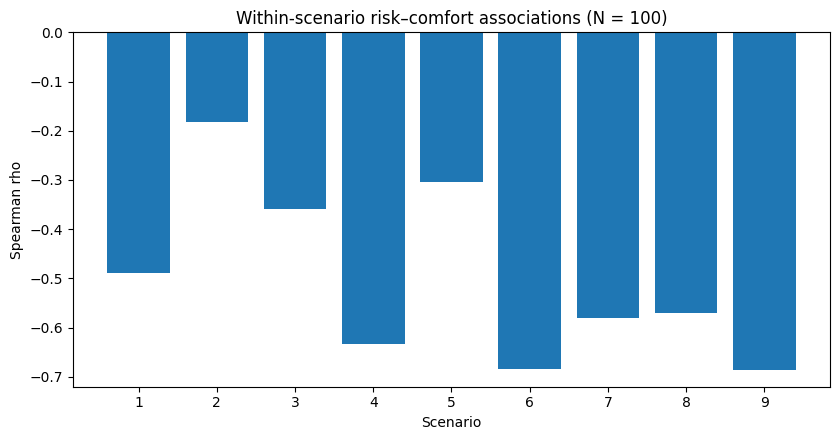

In [6]:
mean_risk_person = risk.mean(axis=1)
mean_comfort_person = comfort.mean(axis=1)
pooled_rho = stats.spearmanr(mean_risk_person, mean_comfort_person)
overall_spearman = [{
    "Comparison": "Educator mean risk versus educator mean comfort",
    "N educators": N_EXPECTED, "Spearman rho": float(pooled_rho.statistic),
    "Unadjusted p": float(pooled_rho.pvalue),
}]
write_csv("RQ3_spearman_participant_average.csv", overall_spearman,
          ["Comparison", "N educators", "Spearman rho", "Unadjusted p"])
print(f"Participant-level risk–comfort Spearman rho = {pooled_rho.statistic:.3f}; "
      f"p {pretty_p(pooled_rho.pvalue)}")

scenario_spearman = []
for j, scenario in enumerate(SCENARIOS):
    result = stats.spearmanr(risk[:, j], comfort[:, j])
    scenario_spearman.append({"Scenario": scenario, "N educators": N_EXPECTED,
                              "Spearman rho": float(result.statistic),
                              "Unadjusted p": float(result.pvalue)})
for row, adj in zip(scenario_spearman,
                    holm_adjust([r["Unadjusted p"] for r in scenario_spearman])):
    row["Holm-adjusted p"] = float(adj)
    row["Significant after Holm"] = bool(adj < ALPHA)
show_table("Risk–comfort correlations within each scenario", [{
    **r, "Spearman rho": f"{r['Spearman rho']:.3f}",
    "Unadjusted p": pretty_p(r["Unadjusted p"]),
    "Holm-adjusted p": pretty_p(r["Holm-adjusted p"]),
} for r in scenario_spearman], ["Scenario", "Spearman rho", "Unadjusted p",
                             "Holm-adjusted p", "Significant after Holm"])
write_csv("RQ3_spearman_by_scenario_holm.csv", scenario_spearman,
          ["Scenario", "N educators", "Spearman rho", "Unadjusted p",
           "Holm-adjusted p", "Significant after Holm"])

fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.bar(np.arange(1, 10), [r["Spearman rho"] for r in scenario_spearman])
ax.set(xlabel="Scenario", ylabel="Spearman rho",
       title="Within-scenario risk–comfort associations (N = 100)")
ax.set_xticks(np.arange(1, 10))
ax.axhline(0, linewidth=0.7)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "RQ3_risk_comfort_spearman_by_scenario.png", dpi=160)
plt.show()

## 7. Selected Kruskal–Wallis comparisons: risk by judgment

Compare risk ratings among the *independent* judgment groups Yes, No, and
Depends **within a single scenario**. This reproduces the previously
reported Scenario 6 comparison and adds a selected Scenario 9 comparison.
Responses of “I do not know” are excluded from these *specific* planned
three-group tests, not from the study. Their counts are reported explicitly.
Holm adjustment is used across these two exploratory Kruskal–Wallis tests.

Kruskal–Wallis establishes a difference in group distributions, not whether
any judgment is legally correct. It does not identify which pair differs.

In [7]:
selected_scenarios = [6, 9]
kruskal_results = []
kruskal_group_stats = []
for scenario_num in selected_scenarios:
    column = scenario_num - 1
    levels = ("Yes", "No", "Depends")
    groups = [risk[judgment[:, column] == level, column] for level in levels]
    if any(len(group) == 0 for group in groups):
        raise ValueError("Kruskal-Wallis requires a nonempty group for each comparison.")
    result = stats.kruskal(*groups)
    n_excluded = int(np.sum(judgment[:, column] == "I do not know"))
    kruskal_results.append({
        "Scenario": SCENARIOS[column], "Included judgments": "Yes / No / Depends",
        "N in test": int(sum(map(len, groups))), "I do not know excluded": n_excluded,
        "Kruskal H": float(result.statistic), "df": 2,
        "Unadjusted p": float(result.pvalue),
    })
    for level, group in zip(levels, groups):
        kruskal_group_stats.append({
            "Scenario": SCENARIOS[column], "Judgment": level,
            "N": len(group), "Median risk": float(np.median(group)),
            "Mean risk": float(np.mean(group)),
        })
for row, adj in zip(kruskal_results,
                    holm_adjust([r["Unadjusted p"] for r in kruskal_results])):
    row["Holm-adjusted p"] = float(adj)
    row["Significant after Holm"] = bool(adj < ALPHA)
show_table("Selected Kruskal–Wallis tests", [{
    **r, "Kruskal H": f"{r['Kruskal H']:.3f}",
    "Unadjusted p": pretty_p(r["Unadjusted p"]),
    "Holm-adjusted p": pretty_p(r["Holm-adjusted p"]),
} for r in kruskal_results], ["Scenario", "N in test", "I do not know excluded",
                             "Kruskal H", "Unadjusted p", "Holm-adjusted p"])
show_table("Risk by selected compliance-judgment group", [
    {**r, "Mean risk": f"{r['Mean risk']:.2f}"} for r in kruskal_group_stats
], ["Scenario", "Judgment", "N", "Median risk", "Mean risk"])
write_csv("RQ3_kruskal_risk_by_judgment_holm.csv", kruskal_results,
          ["Scenario", "Included judgments", "N in test", "I do not know excluded",
           "Kruskal H", "df", "Unadjusted p", "Holm-adjusted p", "Significant after Holm"])
write_csv("RQ3_kruskal_group_descriptives.csv", kruskal_group_stats,
          ["Scenario", "Judgment", "N", "Median risk", "Mean risk"])


Selected Kruskal–Wallis tests
Scenario    N in test  I do not know excluded  Kruskal H  Unadjusted p  Holm-adjusted p
----------  ---------  ----------------------  ---------  ------------  ---------------
Scenario 6  93         7                       49.031     < .001        < .001         
Scenario 9  97         3                       57.814     < .001        < .001         

Risk by selected compliance-judgment group
Scenario    Judgment  N   Median risk  Mean risk
----------  --------  --  -----------  ---------
Scenario 6  Yes       39  4.0          3.85     
Scenario 6  No        23  2.0          1.74     
Scenario 6  Depends   31  3.0          2.97     
Scenario 9  Yes       32  4.0          4.00     
Scenario 9  No        54  2.0          1.72     
Scenario 9  Depends   11  3.0          3.09     


## 8. Exploratory ordinal GEE: perceived risk as the outcome

**Outcome:** five-point perceived compliance risk (1 = very low, 5 = very high).
**Predictors:** five-point comfort rating, Q6 self-assessed FERPA knowledge,
recent FERPA training (Q15), and scenario fixed effects.
**Clusters:** original educators. All nine scenario rows for an educator are
treated as correlated within that educator.

We use `statsmodels.OrdinalGEE`, with a binomial cumulative-logit parameterization
and **participant-cluster-robust standard errors**. The primary model has an
independence *working* correlation structure, matching the earlier exploratory
analysis; this does **not** mean treating repeated ratings as independent for
uncertainty estimation. A second model with exchangeable working correlation
serves as a sensitivity analysis.

`OrdinalGEE` represents the ordinal outcome by cumulative cutpoints. Its
comfort coefficient models the odds of exceeding a given risk threshold.
Negative beta / OR below one indicates lower odds of higher risk at greater
comfort, holding other predictors constant. Odds ratios are associations,
not causal effects. Proportional-odds and working-correlation assumptions
should be examined before relying on the model for publication.

In [8]:
N_SCENARIOS = len(SCENARIOS)
cluster = np.repeat(np.arange(N_EXPECTED), N_SCENARIOS)
scenario_index = np.tile(np.arange(N_SCENARIOS), N_EXPECTED)
long_risk = risk.reshape(-1).astype(int)
long_comfort = comfort.reshape(-1)
long_knowledge = np.repeat(knowledge, N_SCENARIOS)
long_training = np.repeat(recent_training, N_SCENARIOS)
predictor_names = [
    "Comfort (one-point increase)", "Self-assessed knowledge Q6 (one-point increase)",
    "Recent training Q15 (Yes vs No)",
] + [f"Scenario {i} vs Scenario 1" for i in range(2, 10)]

# Do not add a constant: OrdinalGEE estimates its own cumulative thresholds.
exog = np.column_stack([
    long_comfort, long_knowledge, long_training,
    *[(scenario_index == index).astype(float) for index in range(1, N_SCENARIOS)],
]).astype(float)


def fit_ordinal_gee(cov_struct, label):
    model = OrdinalGEE(long_risk, exog, groups=cluster, cov_struct=cov_struct)
    result = model.fit(maxiter=150, ctol=1e-6, cov_type="robust")
    if not result.converged:
        raise RuntimeError(f"Ordinal GEE did not converge: {label}")
    n_thresholds = len(np.unique(long_risk)) - 1
    estimates = np.asarray(result.params, dtype=float)[n_thresholds:]
    confidence = np.asarray(result.conf_int(), dtype=float)[n_thresholds:, :]
    pvalues = np.asarray(result.pvalues, dtype=float)[n_thresholds:]
    if len(estimates) != len(predictor_names):
        raise AssertionError("Unexpected ordinal GEE coefficient layout; verify statsmodels version")
    rows = []
    for term, beta, ci, p in zip(predictor_names, estimates, confidence, pvalues):
        rows.append({
            "Working correlation": label, "Predictor": term,
            "Beta": float(beta), "Odds ratio": float(np.exp(beta)),
            "OR CI lower": float(np.exp(ci[0])), "OR CI upper": float(np.exp(ci[1])),
            "Unadjusted p": float(p),
        })
    return rows


gee_primary = fit_ordinal_gee(Independence(), "Independence (robust SE)")
gee_sensitivity = fit_ordinal_gee(Exchangeable(), "Exchangeable (robust SE)")
gee_rows = gee_primary + gee_sensitivity
gee_cols = ["Working correlation", "Predictor", "Beta", "Odds ratio", "OR CI lower",
            "OR CI upper", "Unadjusted p"]
write_csv("RQ3_ordinal_GEE_primary_and_sensitivity.csv", gee_rows, gee_cols)
comfort_gee = [r for r in gee_rows if r["Predictor"] == "Comfort (one-point increase)"]
show_table("Exploratory ordinal GEE: comfort effect", [{
    **r, "Beta": f"{r['Beta']:.3f}", "Odds ratio": f"{r['Odds ratio']:.3f}",
    "OR CI lower": f"{r['OR CI lower']:.3f}",
    "OR CI upper": f"{r['OR CI upper']:.3f}",
    "Unadjusted p": pretty_p(r["Unadjusted p"]),
} for r in comfort_gee], ["Working correlation", "Beta", "Odds ratio",
                           "OR CI lower", "OR CI upper", "Unadjusted p"])
print("Primary GEE is a population-average, exploratory association model.")
print("Its working-independence structure uses participant-cluster-robust SEs.")


Exploratory ordinal GEE: comfort effect
Working correlation       Beta    Odds ratio  OR CI lower  OR CI upper  Unadjusted p
------------------------  ------  ----------  -----------  -----------  ------------
Independence (robust SE)  -0.978  0.376       0.300        0.472        < .001      
Exchangeable (robust SE)  -1.112  0.329       0.254        0.426        < .001      
Primary GEE is a population-average, exploratory association model.
Its working-independence structure uses participant-cluster-robust SEs.


## 9. Results checklist and interpretation notes

CSV outputs and charts are saved in `RQ3_outputs/`. None of the exports
contains personal IDs or written explanations.

**Statistical reporting safeguards:**

- Friedman is the overall repeated-scenario comparison; Kendall's W is its
  effect-size measure. Neither indicates legal correctness.
- The selected paired tests were defined as S7–S8 and S4–S6. Holm correction
  is applied across the four related paired comparisons.
- Spearman correlations use one average risk and comfort value per educator,
  or one correlation per scenario. The nine scenario-specific correlations
  are treated as a separate family for Holm correction.
- Kruskal-Wallis tests are within S6 and S9, where the judgment groups are
  independent for that *single* scenario; the “I do not know” group is not
  included in the chosen three-group comparisons.
- GEE is exploratory, uses educator-level clustering and a proportional-odds
  formulation, and should be checked for sensitivity to model specification.
- The observational survey cannot establish that vendor practices, comfort,
  knowledge, or training caused differences in responses.

In [9]:
print("\nCompleted RQ3 statistical analyses for N = 100.")
print("Friedman risk chi-square:", round(friedman_results[0]["Friedman chi-square"], 3))
print("Friedman comfort chi-square:", round(friedman_results[1]["Friedman chi-square"], 3))
print("Participant-level Spearman rho:", round(float(pooled_rho.statistic), 3))
print("S6 Kruskal H:", round(kruskal_results[0]["Kruskal H"], 3))
print("Primary ordinal GEE comfort OR:", round(gee_primary[0]["Odds ratio"], 3))
print("Exported aggregate results to:", OUTPUT_DIR.resolve())
for output in sorted(OUTPUT_DIR.iterdir()):
    if output.is_file():
        print(" -", output.name)


Completed RQ3 statistical analyses for N = 100.
Friedman risk chi-square: 524.964
Friedman comfort chi-square: 414.415
Participant-level Spearman rho: -0.523
S6 Kruskal H: 49.031
Primary ordinal GEE comfort OR: 0.376
Exported aggregate results to: /mnt/data/RQ3_outputs
 - RQ3_friedman_kendall_w.csv
 - RQ3_kruskal_group_descriptives.csv
 - RQ3_kruskal_risk_by_judgment_holm.csv
 - RQ3_ordinal_GEE_primary_and_sensitivity.csv
 - RQ3_risk_comfort_by_scenario.png
 - RQ3_risk_comfort_spearman_by_scenario.png
 - RQ3_scenario_descriptive_summary.csv
 - RQ3_spearman_by_scenario_holm.csv
 - RQ3_spearman_participant_average.csv
 - RQ3_wilcoxon_selected_pairs_holm.csv
